In [1]:
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [2]:
from datasets import load_dataset
imdb_dataset = load_dataset("imdb")
split = imdb_dataset["train"].train_test_split(train_size=0.8, seed=42)
imdb_train_set, imdb_valid_set = split["train"], split["test"]
imdb_test_set = imdb_dataset["test"]

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:103: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [3]:
from collections import Counter
import pandas as pd

def check_balance(dataset, name):
    labels = dataset["label"]
    counts = Counter(labels)
    total = len(labels)
    
    print(f"\n{'='*40}")
    print(f"  {name} ({total} samples)")
    print(f"{'='*40}")
    for label, count in sorted(counts.items()):
        label_name = "Positive" if label == 1 else "Negative"
        print(f"  {label_name} (label={label}): {count:>6} ({count/total*100:.2f}%)")

check_balance(imdb_train_set, "Train Set")
check_balance(imdb_valid_set, "Validation Set")
check_balance(imdb_test_set,  "Test Set")


  Train Set (20000 samples)
  Negative (label=0):  10006 (50.03%)
  Positive (label=1):   9994 (49.97%)

  Validation Set (5000 samples)
  Negative (label=0):   2494 (49.88%)
  Positive (label=1):   2506 (50.12%)

  Test Set (25000 samples)
  Negative (label=0):  12500 (50.00%)
  Positive (label=1):  12500 (50.00%)


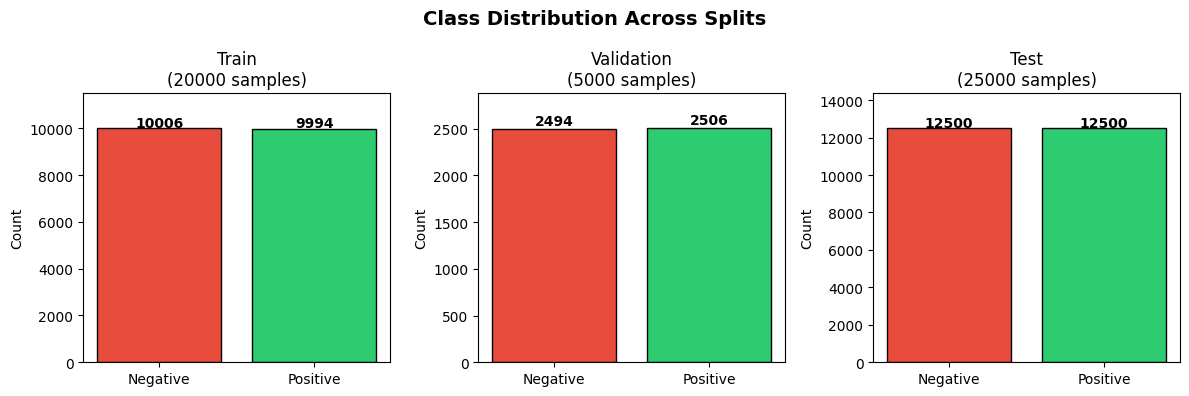

In [4]:
import matplotlib.pyplot as plt

def plot_balance(datasets_dict):
    fig, axes = plt.subplots(1, len(datasets_dict), figsize=(12, 4))
    
    for ax, (name, dataset) in zip(axes, datasets_dict.items()):
        labels = dataset["label"]
        counts = Counter(labels)
        
        bars = ax.bar(
            ["Negative", "Positive"],
            [counts[0], counts[1]],
            color=["#e74c3c", "#2ecc71"],
            edgecolor="black"
        )
        # Add count labels on bars
        for bar, count in zip(bars, [counts[0], counts[1]]):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                    str(count), ha="center", fontweight="bold")
        
        ax.set_title(f"{name}\n({len(labels)} samples)")
        ax.set_ylabel("Count")
        ax.set_ylim(0, max(counts.values()) * 1.15)
    
    plt.suptitle("Class Distribution Across Splits", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig("class_balance.png", dpi=150)
    plt.show()

plot_balance({
    "Train":      imdb_train_set,
    "Validation": imdb_valid_set,
    "Test":       imdb_test_set
})

In [5]:
import tokenizers
bpe_model = tokenizers.models.BPE(unk_token="<unk>")
bpe_tokenizer = tokenizers.Tokenizer(bpe_model)
bpe_tokenizer.pre_tokenizer = tokenizers.pre_tokenizers.Whitespace()
special_tokens = ["<pad>", "<unk>"]
bpe_trainer = tokenizers.trainers.BpeTrainer(vocab_size=1000,
special_tokens=special_tokens)
train_reviews = [review["text"].lower() for review in imdb_train_set]
bpe_tokenizer.train_from_iterator(train_reviews, bpe_trainer)

In [6]:
some_review = "what an awesome movie!"
bpe_encoding = bpe_tokenizer.encode(some_review)
bpe_encoding.tokens


['what', 'an', 'aw', 'es', 'ome', 'movie', '!']

In [7]:
bpe_tokenizer.enable_padding(pad_id=0, pad_token="<pad>")
bpe_tokenizer.enable_truncation(max_length=500)

In [8]:
import torch

In [9]:
bpe_encodings = bpe_tokenizer.encode_batch(train_reviews[:3])
bpe_batch_ids = torch.tensor([encoding.ids for encoding in bpe_encodings])
bpe_batch_ids

tensor([[159, 402, 176, 246,  61, 782, 156, 737, 252,  42, 239,  51, 154, 460,
         917,  17, 272, 156, 737, 576, 215, 976, 275,  42, 199,  44, 554,  42,
         192, 585,  57, 160, 259, 170, 157, 143, 138, 159, 402,  11, 589, 152,
           5, 819, 168, 230,   5, 521, 924, 981, 962, 250,  61,  10,  60, 426,
         526, 959,  60, 138, 199, 150, 319,  15, 363, 141, 957, 694,  47, 696,
          61, 875, 138, 960, 337, 414, 140, 157, 385, 174, 433, 161, 221, 145,
         213,  17, 549,  15, 151,  10,  60,  55, 416, 146, 407, 144, 182, 303,
         151, 141,  17, 138, 547, 538, 528, 768,  54, 335,  42, 203,  44, 270,
          46, 153, 876, 141, 919, 233, 522, 172, 141, 719, 162, 807, 279,  17,
         138,  45,  66,  55, 188, 989, 156, 378, 698, 301, 296, 689, 212, 558,
         926, 148,  17,  44, 270,  46, 141,  47, 279, 302, 171, 152, 787,  15,
         153, 522, 172, 766, 205, 156, 234, 677, 161, 139, 513, 146, 370, 251,
         219, 162, 197, 162, 166,  50, 265,  47, 266

In [10]:
attention_mask = torch.tensor([encoding.attention_mask for encoding in bpe_encodings])
lengths = attention_mask.sum(dim=-1)
attention_mask,lengths

(tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
          1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
         [1, 1, 1, 1, 1,

bbpe tokinezer

In [11]:
import transformers
gpt2_tokenizer = transformers.AutoTokenizer.from_pretrained("gpt2")
gpt2_encoding = gpt2_tokenizer(train_reviews[:3], truncation=True,
max_length=500)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

wordpiece tokenizer

In [12]:
bert_tokenizer = transformers.AutoTokenizer.from_pretrained("bert-base-uncased")
bert_encoding = bert_tokenizer(train_reviews[:3], padding=True,
truncation=True, max_length=500,
return_tensors="pt")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

unigram lm tokinezer

In [13]:
albert_tokenizer = transformers.AutoTokenizer.from_pretrained("albert-base-v2")
albert_encoding = albert_tokenizer(train_reviews[:3], padding=True, truncation=True, max_length=500, return_tensors="pt")

config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/760k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

wrap up your own tokinezer

In [14]:
hf_tokenizer = transformers.PreTrainedTokenizerFast(
tokenizer_object=bpe_tokenizer)
hf_encodings = hf_tokenizer(train_reviews[:3], padding=True,truncation=True, max_length=500, return_tensors="pt")

In [15]:
def collate_fn(batch, tokenizer=bert_tokenizer):
    reviews = [review["text"] for review in batch]
    labels = [[review["label"]] for review in batch]
    encodings = tokenizer(reviews, padding=True, truncation=True,
    max_length=200, return_tensors="pt")
    labels = torch.tensor(labels, dtype=torch.float32)
    return encodings, labels

In [16]:
batch_size = 256
imdb_train_loader = DataLoader(imdb_train_set, batch_size=batch_size,collate_fn=collate_fn, shuffle=True)
imdb_valid_loader = DataLoader(imdb_valid_set, batch_size=batch_size,collate_fn=collate_fn)
imdb_test_loader = DataLoader(imdb_test_set, batch_size=batch_size,collate_fn=collate_fn)

In [17]:
class SentimentAnalysisModel(nn.Module):
    def __init__(self, vocab_size, n_layers=2, embed_dim=128, hidden_dim=64,
    pad_id=0, dropout=0.2):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim,
        padding_idx=pad_id)
        self.gru = nn.GRU(embed_dim, hidden_dim, num_layers=n_layers,
        batch_first=True, dropout=dropout)
        self.output = nn.Linear(hidden_dim, 1)
    def forward(self, encodings):
        embeddings = self.embed(encodings["input_ids"])
        _outputs, hidden_states = self.gru(embeddings)
        return self.output(hidden_states[-1])

>>> from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
>>> sequences = torch.tensor([[1, 2, 0, 0], [5, 6, 7, 8]])
>>> packed = pack_padded_sequence(sequences, lengths=(2, 4),
...
enforce_sorted=False, batch_first=True)
...
>>> packed
PackedSequence(data=tensor([5, 1, 6, 2, 7, 8]), [...])
>>> padded, lengths = pad_packed_sequence(packed, batch_first=True)
>>> padded, lengths(tensor([[1, 2, 0, 0],
[5, 6, 7, 8]]),
tensor([2, 4])

In [18]:
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

In [20]:
class SentimentAnalysisModel(nn.Module):
    def __init__(self, vocab_size, n_layers=2, embed_dim=128, hidden_dim=64,
    pad_id=0, dropout=0.2):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim,
        padding_idx=pad_id)
        self.gru = nn.GRU(embed_dim, hidden_dim, num_layers=n_layers,
        batch_first=True, dropout=dropout,bidirectional=True)
        self.output = nn.Linear(2*hidden_dim, 1)
    def forward(self, encodings):
        embeddings = self.embed(encodings["input_ids"])
        lengths = encodings["attention_mask"].sum(dim=1)
        packed = pack_padded_sequence(embeddings, lengths=lengths.cpu(),
        batch_first=True, enforce_sorted=False)
        _outputs, hidden_states = self.gru(packed)
        n_dims = self.output.in_features
        top_states = hidden_states[-2:].permute(1, 0, 2).reshape(-1, n_dims)
        return self.output(top_states)

If you pass a packed sequence to an nn.GRU module, its outputs will also be a packed sequence, and you will
need to convert it back to a padded tensor before you can pass it to the next layers. Luckily, we don’t need
these outputs for our sentiment analysis model, only the hidden states.

reusing pretrained embeddings and large models

In [21]:
bert_model = transformers.AutoModel.from_pretrained("bert-base-uncased")
bert_model.embeddings.word_embeddings

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding(30522, 768, padding_idx=0)

In [22]:
class SentimentAnalysisModelPreEmbeds(nn.Module):
    def __init__(self, pretrained_embeddings, n_layers=2, hidden_dim=64,
                 dropout=0.2):
        super().__init__()
        weights = pretrained_embeddings.weight.data
        self.embed = nn.Embedding.from_pretrained(weights, freeze=True)
        embed_dim = weights.shape[-1]
        self.gru = nn.GRU(embed_dim, hidden_dim, num_layers=n_layers,
                          batch_first=True, dropout=dropout, bidirectional=True)
        self.output = nn.Linear(2 * hidden_dim, 1)

    def forward(self, encodings):
        embeddings = self.embed(encodings["input_ids"])
        lengths = encodings["attention_mask"].sum(dim=1)
        packed = pack_padded_sequence(embeddings, lengths=lengths.cpu(),
                                      batch_first=True, enforce_sorted=False)
        _outputs, hidden_states = self.gru(packed)
        n_dims = self.output.in_features
        top_states = hidden_states[-2:].permute(1, 0, 2).reshape(-1, n_dims)
        return self.output(top_states)

In [23]:
%pip install torchmetrics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 21.4 MB/s eta 0:00:0000:01


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [26]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=2, factor=0.5, epoch_callback=None):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        for index, (X_batch, y_batch) in enumerate(train_loader):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
            train_metric = metric.compute().item()
            print(f"\rBatch {index + 1}/{len(train_loader)}", end="")
            print(f", loss={total_loss/(index+1):.4f}", end="")
            print(f", {train_metric=:.2%}", end="")
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(f"\rEpoch {epoch + 1}/{n_epochs},                      "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.2%}, "
              f"valid metric: {history['valid_metrics'][-1]:.2%}")
    return history

In [27]:
torch.manual_seed(42)

imdb_model_bert_embeds = SentimentAnalysisModelPreEmbeds(
    bert_model.embeddings.word_embeddings).to(device)

n_epochs = 10
xentropy = nn.BCEWithLogitsLoss()
optimizer = torch.optim.NAdam(imdb_model_bert_embeds.parameters())
accuracy = torchmetrics.Accuracy(task="binary").to(device)

history = train(imdb_model_bert_embeds, optimizer, xentropy, accuracy,
                imdb_train_loader, imdb_valid_loader, n_epochs)

Epoch 1/10,                      train loss: 0.6894, train metric: 55.42%, valid metric: 63.76%
Epoch 2/10,                      train loss: 0.6468, train metric: 63.85%, valid metric: 69.44%
Epoch 3/10,                      train loss: 0.5549, train metric: 72.26%, valid metric: 69.36%
Epoch 4/10,                      train loss: 0.4775, train metric: 77.46%, valid metric: 64.16%
Epoch 5/10,                      train loss: 0.4121, train metric: 81.13%, valid metric: 82.06%
Epoch 6/10,                      train loss: 0.3688, train metric: 83.21%, valid metric: 83.62%
Epoch 7/10,                      train loss: 0.3313, train metric: 85.33%, valid metric: 80.08%
Epoch 8/10,                      train loss: 0.3072, train metric: 86.70%, valid metric: 78.44%
Epoch 9/10,                      train loss: 0.2925, train metric: 87.54%, valid metric: 69.38%
Epoch 10/10,                      train loss: 0.2548, train metric: 89.32%, valid metric: 81.52%


In [29]:
imdb_model_bert_embeds.eval()

test_accuracy = torchmetrics.Accuracy(task="binary").to(device)
test_loss = 0.0
n_batches = 0

with torch.no_grad():
    for encodings, labels in imdb_test_loader:
        encodings = {k: v.to(device) for k, v in encodings.items()}
        labels = labels.to(device)

        logits = imdb_model_bert_embeds(encodings)
        loss = xentropy(logits.squeeze(), labels.float().squeeze())  # fix here
        test_accuracy.update(logits.squeeze(), labels.squeeze())     # fix here too
        test_loss += loss.item()
        n_batches += 1

final_loss = test_loss / n_batches
final_acc = test_accuracy.compute().item()

print(f"Test Loss: {final_loss:.4f}")
print(f"Test Accuracy: {final_acc:.4f}")

Test Loss: 0.4488
Test Accuracy: 0.8150
